# **lec09. 시계열/금융을 위한 Pandas**

In [1]:
import os
# TensorFlow 안내 및 경고 로그 끄기 (3 = ERROR/FATAL 로그만 표시)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# oneDNN 최적화 관련 안내 문구 숨기기
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
# absl 라이브러리 초기화 전 경고(WARNING: All log messages...) 숨기기
os.environ['ABSL_LOGGING_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings(action='ignore')

from sklearn import set_config
set_config(display="text")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)

from sklearn.model_selection import train_test_split   #---- 문제답 분리

from keras.models import Sequential
#from keras.layers import Conv2D, MaxPooling2D  #---- CNN
from tensorflow.keras.layers import SimpleRNN , LSTM, Input, Reshape  #-----RNN
from keras.layers import Dense, Flatten                      #---- FC

#---------------------- 한글 폰트 지정 -----------------------
plt.rcParams["axes.unicode_minus"] = False                   # 마이너스 기호 깨짐 방지

#plt.rcParams["font.family"] = "Malgun Gothic"               #--------------윈도우 인 경우 
import matplotlib.font_manager as fm                         #--------------리눅스인 경우
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams["font.family"] = font_prop.get_name()

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

import FinanceDataReader as fdr

# **Data Load**

In [2]:
df = fdr.DataReader('010950')
df.columns = df.columns.str.lower()
df = df[['open', 'close']]
df = df[-10:].copy()
df.head(2)

,open,close
Date,,
2026-09-17,143600,152800
2026-09-18,153600,149700


# 금융 Pandas

## shift(N)
* 전일대비 가격 증감

In [3]:
df['shift'] = df['close'].shift(1)
df['close-shift'] = df['close'] - df['shift']
df

,open,close,shift,close-shift
Date,,,,
2026-09-17,143600,152800,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0
2026-09-21,149700,153900,149700.0,4200.0
2026-09-22,147400,153200,153900.0,-700.0
2026-09-23,154600,156500,153200.0,3300.0
2026-09-28,155900,164000,156500.0,7500.0
2026-09-29,163700,158200,164000.0,-5800.0
2026-09-30,159700,162000,158200.0,3800.0
2026-10-01,161800,151300,162000.0,-10700.0


## diff(N)
* N일 대비 가격 증감
* df['close'].diff(1) == df['close'] - df['close'].shift(1)

In [4]:
df['diff'] = df['close'].diff(1)
df

,open,close,shift,close-shift,diff
Date,,,,,
2026-09-17,143600,152800,NaN,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0,-3100.0
2026-09-21,149700,153900,149700.0,4200.0,4200.0
2026-09-22,147400,153200,153900.0,-700.0,-700.0
2026-09-23,154600,156500,153200.0,3300.0,3300.0
2026-09-28,155900,164000,156500.0,7500.0,7500.0
2026-09-29,163700,158200,164000.0,-5800.0,-5800.0
2026-09-30,159700,162000,158200.0,3800.0,3800.0
2026-10-01,161800,151300,162000.0,-10700.0,-10700.0


## pct_change(N)
* 전일 대비 증감률
* 현재가격 - N일가격 백분위 변화율

In [5]:
df['pct'] = df['close'].pct_change(1)
df

,open,close,shift,close-shift,diff,pct
Date,,,,,,
2026-09-17,143600,152800,NaN,NaN,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0,-3100.0,-0.020288
2026-09-21,149700,153900,149700.0,4200.0,4200.0,0.028056
2026-09-22,147400,153200,153900.0,-700.0,-700.0,-0.004548
2026-09-23,154600,156500,153200.0,3300.0,3300.0,0.021540
2026-09-28,155900,164000,156500.0,7500.0,7500.0,0.047923
2026-09-29,163700,158200,164000.0,-5800.0,-5800.0,-0.035366
2026-09-30,159700,162000,158200.0,3800.0,3800.0,0.024020
2026-10-01,161800,151300,162000.0,-10700.0,-10700.0,-0.066049


## rolling(N) : 이동평균
* N일동안의 데이터 집계
* 이동평균 : 5, 10, 20, 60 ,120, 200

In [6]:
df['rolling'] = df['close'].rolling(window=3).mean()
df

,open,close,shift,close-shift,diff,pct,rolling
Date,,,,,,,
2026-09-17,143600,152800,NaN,NaN,NaN,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0,-3100.0,-0.020288,NaN
2026-09-21,149700,153900,149700.0,4200.0,4200.0,0.028056,152133.333333
2026-09-22,147400,153200,153900.0,-700.0,-700.0,-0.004548,152266.666667
2026-09-23,154600,156500,153200.0,3300.0,3300.0,0.021540,154533.333333
2026-09-28,155900,164000,156500.0,7500.0,7500.0,0.047923,157900.000000
2026-09-29,163700,158200,164000.0,-5800.0,-5800.0,-0.035366,159566.666667
2026-09-30,159700,162000,158200.0,3800.0,3800.0,0.024020,161400.000000
2026-10-01,161800,151300,162000.0,-10700.0,-10700.0,-0.066049,157166.666667


## resample('주기')
<pre>
D	    일별 (Daily)	  매일 데이터 집계
W	    주별 (Weekly)	  매주 일요일 기준
ME	    월말 (Month-end)	  각 달의 마지막 날 기준
MS	    월초 (Month-Start)	  각 달의 첫 번째 날 기준
Q	    분기말 (Quarter-end)	  3, 6, 9, 12월 말 기준
YS AS	연초 (Year-Start)	  매년 1월 1일 기준
YE AE	연말 (Year-end)	          매년 12월 31일 기준
H	    시간별 (Hourly)	  매 시간
T min	분별 (Minute)	          매 분
S	    초별 (Second)	  매 초

In [7]:
df = fdr.DataReader('010950')
df.columns = df.columns.str.lower()
df = df[['open', 'close']]
df = df[-100:].copy()
df

,open,close
Date,,
2026-05-08,118600,116800
2026-05-11,118700,110900
2026-05-12,112400,114300
2026-05-13,117300,115300
2026-05-14,114200,115000
...,...,...
2026-09-28,155900,164000
2026-09-29,163700,158200
2026-09-30,159700,162000


In [8]:
min(df.index), max(df.index)

(Timestamp('2026-05-08 00:00:00'), Timestamp('2026-10-02 00:00:00'))

In [9]:
df['close'].resample('ME').mean()

Date
2026-05-31    111046.666667
2026-06-30    107633.333333
2026-07-31    132154.545455
2026-08-31    139535.000000
2026-09-30    154115.000000
2026-10-31    158250.000000
Freq: ME, Name: close, dtype: float64

## 결측채우기

In [10]:
df['shift'] = df['close'].shift(5)
df.head(8)

,open,close,shift
Date,,,
2026-05-08,118600,116800,NaN
2026-05-11,118700,110900,NaN
2026-05-12,112400,114300,NaN
2026-05-13,117300,115300,NaN
2026-05-14,114200,115000,NaN
2026-05-15,114100,112100,116800.0
2026-05-18,113800,111500,110900.0
2026-05-19,111600,110100,114300.0


* bfill : 바로 아래 값으로 채우기
* ffill : 바로 위 값으로 채우기

In [11]:
#df['shift'] = df['shift'].fillna(method='ffill')
df['shift'] = df['shift'].bfill()
df.head(8)

,open,close,shift
Date,,,
2026-05-08,118600,116800,116800.0
2026-05-11,118700,110900,116800.0
2026-05-12,112400,114300,116800.0
2026-05-13,117300,115300,116800.0
2026-05-14,114200,115000,116800.0
2026-05-15,114100,112100,116800.0
2026-05-18,113800,111500,110900.0
2026-05-19,111600,110100,114300.0


## 누적 수익률(Cumulative Return)

### 단순 누적 수익률
* $\text{단순 누적 수익률} = \frac{P_t - P_0}{P_0} \times 100 (\%)$

In [12]:
init_price = 10000
today_price = 15000
((today_price - init_price) / init_price ) * 100

50.0

### 기간별 수익률
* $R_{\text{cumulative}} = \left[ (1 + r_1) \times (1 + r_2) \times \dots \times (1 + r_T) \right] - 1$
* (1+R).cumprod() - 1

In [13]:
df['pct'] = df['close'].pct_change()
df['pct'] = df['pct'].bfill()
df.head(3)

,open,close,shift,pct
Date,,,,
2026-05-08,118600,116800,116800.0,-0.050514
2026-05-11,118700,110900,116800.0,-0.050514
2026-05-12,112400,114300,116800.0,0.030658


In [14]:
df['cumprod'] = (1+df['pct']).cumprod() - 1
df.tail(3)

,open,close,shift,pct,cumprod
Date,,,,,
2026-09-30,159700,162000,153900.0,0.024020,0.316924
2026-10-01,161800,151300,153200.0,-0.066049,0.229942
2026-10-02,153900,165200,156500.0,0.091870,0.342938


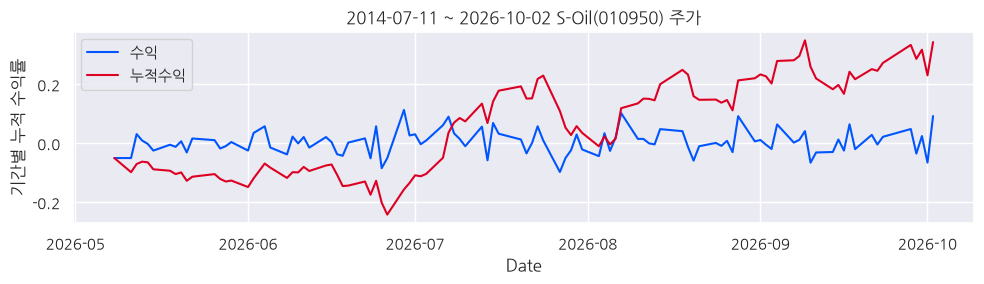

In [15]:
plt.figure(figsize=(10, 3))

sns.lineplot(data=df, x=df.index, y="pct", color="#0055ff"    ,  label="수익")
sns.lineplot(data=df, x=df.index, y="cumprod", color="#dd0022",  label="누적수익")

plt.title("2014-07-11 ~ 2026-10-02 S-Oil(010950) 주가")
plt.ylabel("기간별 누적 수익률")

plt.legend()
plt.tight_layout()
plt.show()

# TA-Lib(Technical Analysis Library)
* 주식, 암호화폐, 외환 등 금융 시장 데이터를 기술적 분석하기 위해 널리 사용되는 오픈소스 라이브러리
* pip install ta-lib

In [16]:
import numpy as np
import pandas as pd
import talib

# --- 2. TA-Lib 지표 계산 ---
# ① 이동평균선 (Moving Average)
# 단순 이동평균(SMA) 외에도 EMA, WMA 등 형식을 지정할 수 있습니다.
df["ma5"] = talib.SMA(df["close"], timeperiod=5)
df['rolling5'] = df['close'].rolling(5).mean()
df.head()

,open,close,shift,pct,cumprod,ma5,rolling5
Date,,,,,,,
2026-05-08,118600,116800,116800.0,-0.050514,-0.050514,NaN,NaN
2026-05-11,118700,110900,116800.0,-0.050514,-0.098476,NaN,NaN
2026-05-12,112400,114300,116800.0,0.030658,-0.070837,NaN,NaN
2026-05-13,117300,115300,116800.0,0.008749,-0.062707,NaN,NaN
2026-05-14,114200,115000,116800.0,-0.002602,-0.065146,114460.0,114460.0


In [17]:
# ② 볼린저 밴드 (Bollinger Bands)
# 상단(MA + 2표준편차), 중단(MA), 하단(MA - 2표준편차) 밴드가 순서대로 반환됩니다.
upperband, middleband, lowerband = talib.BBANDS(
    df["close"],
    timeperiod=5,
    nbdevup=2.0,  # 상단 표준편차 승수
    nbdevdn=2.0,  # 하단 표준편차 승수
    matype=0,  # 0: SMA (단순이동평균)
)

df["BB_Upper"] = upperband
df["BB_Middle"] = middleband
df["BB_Lower"] = lowerband
df.head(10)

,open,close,shift,pct,cumprod,ma5,rolling5,BB_Upper,BB_Middle,BB_Lower
Date,,,,,,,,,,
2026-05-08,118600,116800,116800.0,-0.050514,-0.050514,NaN,NaN,NaN,NaN,NaN
2026-05-11,118700,110900,116800.0,-0.050514,-0.098476,NaN,NaN,NaN,NaN,NaN
2026-05-12,112400,114300,116800.0,0.030658,-0.070837,NaN,NaN,NaN,NaN,NaN
2026-05-13,117300,115300,116800.0,0.008749,-0.062707,NaN,NaN,NaN,NaN,NaN
2026-05-14,114200,115000,116800.0,-0.002602,-0.065146,114460.0,114460.0,118376.324808,114460.0,110543.675192
2026-05-15,114100,112100,116800.0,-0.025217,-0.088721,113520.0,113520.0,116966.505477,113520.0,110073.494523
2026-05-18,113800,111500,110900.0,-0.005352,-0.093598,113640.0,113640.0,116737.353709,113640.0,110542.646291
2026-05-19,111600,110100,114300.0,-0.012556,-0.104979,112800.0,112800.0,116855.613394,112800.0,108744.386606
2026-05-20,110100,110800,115300.0,0.006358,-0.099289,111900.0,111900.0,115277.573093,111900.0,108522.426907


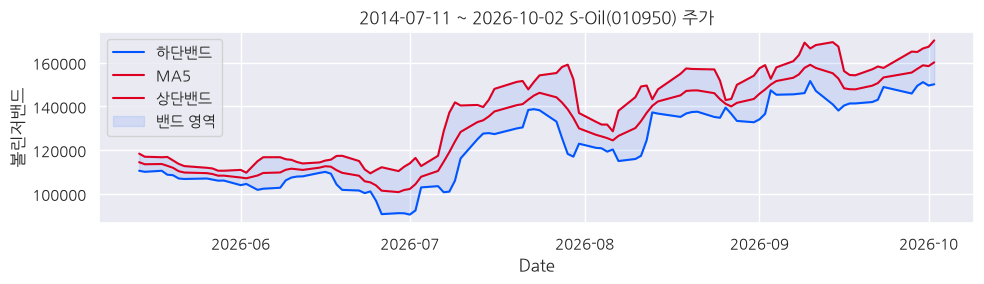

In [18]:
plt.figure(figsize=(10, 3))

sns.lineplot(data=df, x=df.index, y="BB_Lower",  color="#0055ff",  label="하단밴드")
sns.lineplot(data=df, x=df.index, y="ma5",       color="#dd0022",  label="MA5")
sns.lineplot(data=df, x=df.index, y="BB_Upper",  color="#dd0022",  label="상단밴드")

plt.fill_between(df.index, df["BB_Lower"], df["BB_Upper"], color="#0055ff", alpha=0.1, label="밴드 영역")


plt.title("2014-07-11 ~ 2026-10-02 S-Oil(010950) 주가")
plt.ylabel("볼린저밴드")

plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# 상대강도지수 (Relative Strength Index)
df["RSI"] = talib.RSI(df["close"], timeperiod=5)
df.head(10)

,open,close,shift,pct,cumprod,ma5,rolling5,BB_Upper,BB_Middle,BB_Lower,RSI
Date,,,,,,,,,,,
2026-05-08,118600,116800,116800.0,-0.050514,-0.050514,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-11,118700,110900,116800.0,-0.050514,-0.098476,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-12,112400,114300,116800.0,0.030658,-0.070837,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-13,117300,115300,116800.0,0.008749,-0.062707,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-14,114200,115000,116800.0,-0.002602,-0.065146,114460.0,114460.0,118376.324808,114460.0,110543.675192,NaN
2026-05-15,114100,112100,116800.0,-0.025217,-0.088721,113520.0,113520.0,116966.505477,113520.0,110073.494523,32.592593
2026-05-18,113800,111500,110900.0,-0.005352,-0.093598,113640.0,113640.0,116737.353709,113640.0,110542.646291,30.877193
2026-05-19,111600,110100,114300.0,-0.012556,-0.104979,112800.0,112800.0,116855.613394,112800.0,108744.386606,26.768061
2026-05-20,110100,110800,115300.0,0.006358,-0.099289,111900.0,111900.0,115277.573093,111900.0,108522.426907,32.391400


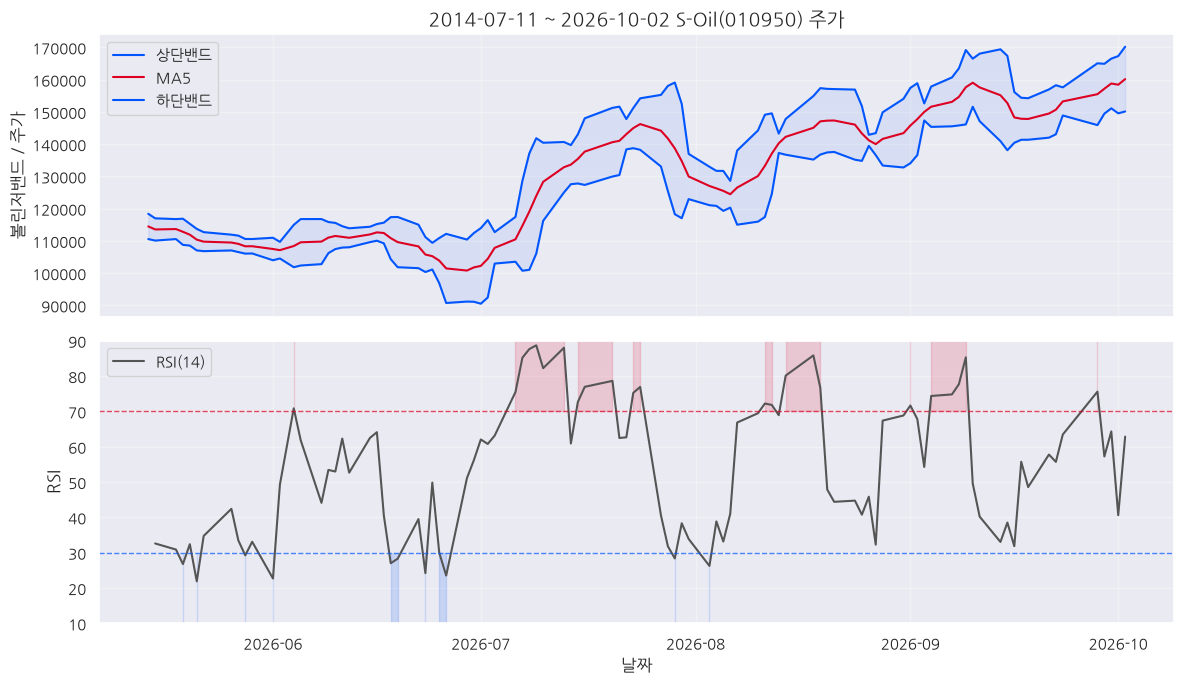

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 2단 서브플롯 생성 (주가/볼린저밴드 + RSI) ---
# gridspec_kw를 통해 상단 차트와 하단 RSI 차트의 비율을 3:1로 조절합니다.
fig, axes = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True
)

# =========================================================================
# [PLOT 1] 볼린저 밴드 & MA5 차트 (axes[0])
# =========================================================================
# 상단/하단 밴드는 대칭감을 위해 같은 색상(#0055ff)으로 지정했습니다.
sns.lineplot(
    data=df, x=df.index, y="BB_Upper", color="#0055ff", label="상단밴드", ax=axes[0]
)
sns.lineplot(
    data=df, x=df.index, y="ma5", color="#dd0022", label="MA5", ax=axes[0]
)
sns.lineplot(
    data=df, x=df.index, y="BB_Lower", color="#0055ff", label="하단밴드", ax=axes[0]
)

# 밴드 내부 채우기 (범례 중복 방지를 위해 label 제거 후 별도 처리)
axes[0].fill_between(
    df.index, df["BB_Lower"], df["BB_Upper"], color="#0055ff", alpha=0.08
)

axes[0].set_title("2014-07-11 ~ 2026-10-02 S-Oil(010950) 주가", fontsize=14)
axes[0].set_ylabel("볼린저밴드 / 주가")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# =========================================================================
# [PLOT 2] RSI 차트 & 30/70 기준선 (axes[1])
# =========================================================================
sns.lineplot(data=df, x=df.index, y="RSI", color="#555555", label="RSI(14)", ax=axes[1])

# 과매수(70) / 과매도(30) 가로 기준선 추가
axes[1].axhline(70, color="#dd0022", linestyle="--", linewidth=1, alpha=0.7)
axes[1].axhline(30, color="#0055ff", linestyle="--", linewidth=1, alpha=0.7)

# (선택 사항) 과매수/과매도 구간 배경 채우기 - 가독성이 좋아집니다.
axes[1].fill_between(
    df.index, 70, 100, where=(df["RSI"] >= 70), color="#dd0022", alpha=0.15
)
axes[1].fill_between(
    df.index, 0, 30, where=(df["RSI"] <= 30), color="#0055ff", alpha=0.15
)

axes[1].set_ylabel("RSI")
axes[1].set_ylim(10, 90)  # RSI 변동을 잘 보이기 위해 y축 범위 제한
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

# --- 레이아웃 마무리 ---
plt.xlabel("날짜")
plt.tight_layout()
plt.show()